In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy import signal
from IPython.display import Audio, display

# Notebook hem proje kökünden hem notebooks klasöründen çalışabilir.
PROJE = Path.cwd().resolve()
if PROJE.name == "notebooks":
    PROJE = PROJE.parent

if not (PROJE / "data" / "raw").is_dir():
    raise FileNotFoundError(
        "Proje klasörü bulunamadı. VS Code'da ses-analizi klasörünü aç."
    )

GRAFIKLER = PROJE / "outputs" / "figures"
GRAFIKLER.mkdir(parents=True, exist_ok=True)

print("Proje:", PROJE)

### 2. Kaydı seç, yükle ve dinle
Bu hücre en son kaydedilen WAV dosyasını seçer.

In [ ]:
dosyalar = sorted(
    (PROJE / "data" / "raw").glob("*.wav"),
    key=lambda p: p.stat().st_mtime,
)

if not dosyalar:
    raise FileNotFoundError(
        "data/raw içinde WAV kaydı yok. Önce src/01_kayit.py dosyasını çalıştır."
    )

DOSYA = dosyalar[-1]

# Belirli bir kaydı seçmek istersen aşağıdaki satırı düzenleyip aç:
# DOSYA = PROJE / "data" / "raw" / "ses_dosyan.wav"

ses, sr = sf.read(DOSYA, dtype="float64", always_2d=True)
kanal_sayisi = ses.shape[1]

# Analizde ilk kanalı kullanacağız.
y = ses[:, 0]

if len(y) == 0:
    raise ValueError("Ses dosyası boş.")

sure = len(y) / sr

print(f"Dosya: {DOSYA.name}")
print(f"Süre: {sure:.2f} saniye")
print(f"Örnekleme hızı: {sr} Hz")
print(f"Kanal sayısı: {kanal_sayisi}")
print(f"Tepe Genliği: {np.max(np.abs(y)):.4f}")

display(Audio(y, rate=sr, normalize=False))

### 3. Tüm kaydın dalga biçimi

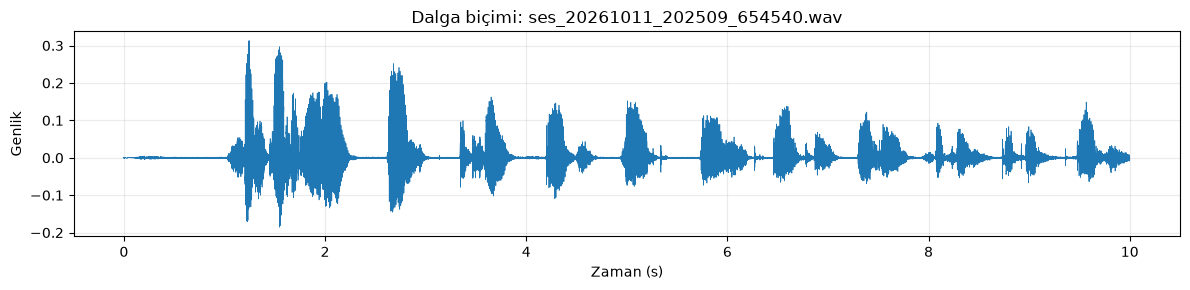

In [4]:
zaman = np.arange(len(y)) / sr

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(zaman, y, linewidth=0.5)
ax.set(
    title=f"Dalga biçimi: {DOSYA.name}",
    xlabel="Zaman (s)",
    ylabel="Genlik",
)
ax.grid(alpha=0.25)
fig.tight_layout()ß

fig.savefig(GRAFIKLER / f"{DOSYA.stem}_dalga_bicimi.png", dpi=300)

plt.show()

### 4. Seçilen konuşma bölümünün spektrumu
Önce dalga biçimine bakarak konuşma içeren bir aralık seçilir. Aşağıdaki başlangıç değerleri 2-3 saniye arasını inceler.

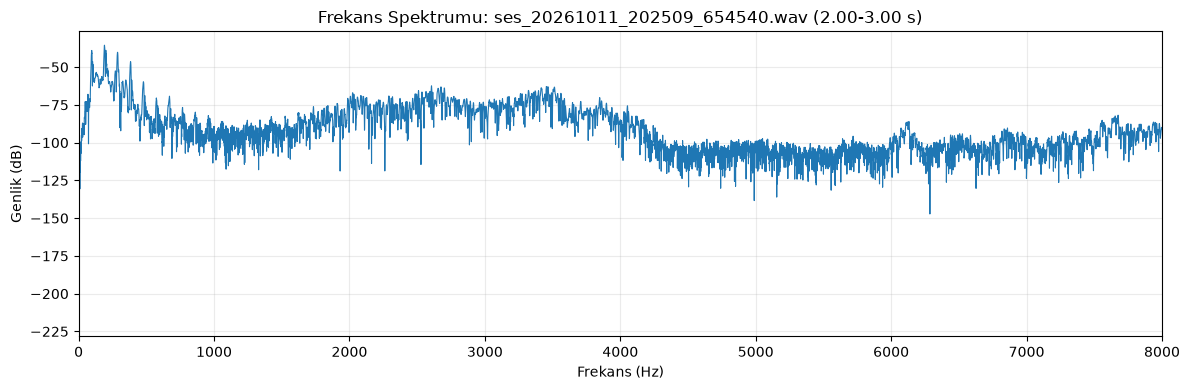

In [5]:
BASLANGIC = 2.0
BITIS = 3.0

if not 0 <= BASLANGIC < BITIS <= sure:
    raise ValueError(f"Aralık hatalı. 0 - {sure:.2f} saniye içinde olmalı. ")


parca = y[round(BASLANGIC * sr) : round(BITIS * sr)]

if len(parca) < 2:
    raise ValueError("Seçilen aralık çok kısa. Daha uzun bir aralık seçin.")

# Hann penceresi, kesilen bölümün sınır etkilerini azaltmak için kullanılır.
pencere = signal.windows.hann(len(parca), sym=False)
fft = np.fft.rfft(parca * pencere)
frekans = np.fft.rfftfreq(len(parca), d=1 / sr)

# Tek taraflı genlik spektrumu
genlik = np.abs(fft) / pencere.sum()
genlik[1:] *= 2  # DC bileşeni hariç tüm genlikleri iki katına çıkar
if len(parca) % 2 == 0:
    genlik[-1] /= 2  # Nyquist frekansı için düzeltme

genlik_db = 20 * np.log10(np.maximum(genlik, 1e-12))  # dB cinsinden genlik, log(0) hatasını önlemek için   

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(frekans, genlik_db, linewidth=0.8)
ax.set(
    title=f"Frekans Spektrumu: {DOSYA.name} ({BASLANGIC:.2f}-{BITIS:.2f} s)",
    xlabel="Frekans (Hz)",
    ylabel="Genlik (dB)",
    xlim=(0, min(8000, sr / 2))
)
ax.grid(alpha=0.25)
fig.tight_layout()

fig.savefig(GRAFIKLER / f"{DOSYA.stem}_spektrum_{BASLANGIC:.2f}-{BITIS:.2f}s.png", dpi=300)
plt.show()

display(Audio(parca, rate=sr, normalize=False))

### 5. Tüm kaydın spektrogramı
25 ms pencere ve yaklaşık 10 ms adımla frekansların zaman içindeki değişimini göstereceğiz.

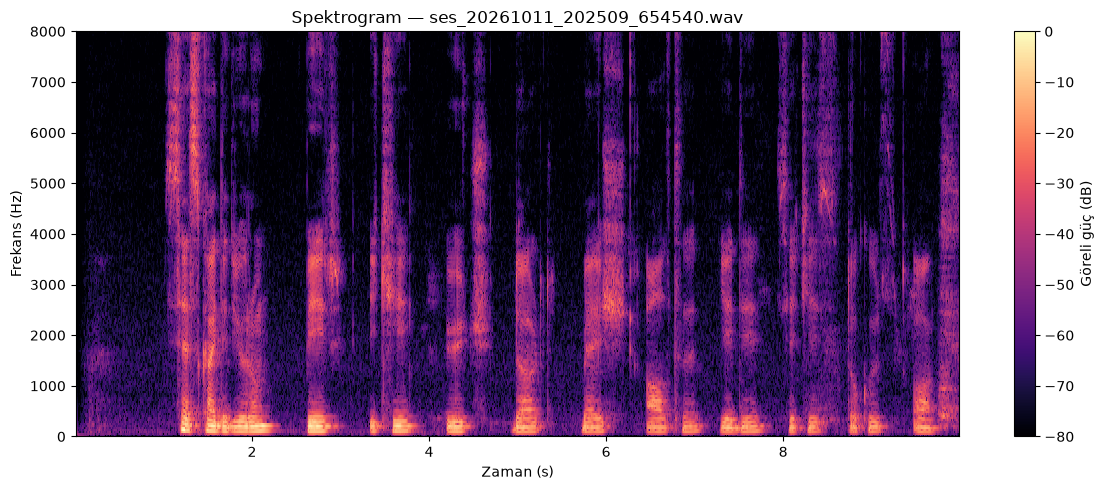

In [6]:
pencere_uzunlugu = min(round(0.025 * sr), len(y))
adim = max(1, round(0.010 * sr))
ortusme = max(0, pencere_uzunlugu - adim)

f, t, guc = signal.spectrogram(
    y,
    fs=sr,
    window="hann",
    nperseg=pencere_uzunlugu,
    noverlap=ortusme,
    detrend=False,
    scaling="density",
    mode="psd",
)

# En güçlü noktayı 0 dB kabul eden göreli gösterim
referans = max(float(guc.max()), 1e-20)
guc_db = 10 * np.log10(
    np.maximum(guc / referans, 1e-8)
)

fig, ax = plt.subplots(figsize=(12, 5))
grafik = ax.pcolormesh(
    t, f, guc_db,
    shading="auto",
    cmap="magma",
    vmin=-80,
    vmax=0,
)

ax.set(
    title=f"Spektrogram — {DOSYA.name}",
    xlabel="Zaman (s)",
    ylabel="Frekans (Hz)",
    ylim=(0, min(8000, sr / 2)),
)

fig.colorbar(
    grafik,
    ax=ax,
    label="Göreli güç (dB)",
)
fig.tight_layout()

fig.savefig(
    GRAFIKLER / f"{DOSYA.stem}_spektrogram.png",
    dpi=150,
)
plt.show()